# MotoTaller IA: análisis de opiniones de clientes con redes recurrentes (GRU / LSTM)

Proyecto de Deep Learning con **datos secuenciales (texto)**. Una red recurrente lee una opinión palabra por palabra y la clasifica como **positiva o negativa**. Caso de uso: un taller de motos que quiere detectar rápido las opiniones negativas de sus clientes.

**Pipeline:** dataset → análisis exploratorio → limpieza → split train/val/test → vectorización → GRU y LSTM → entrenamiento → métricas → curvas → matriz de confusión → predicciones → guardado.

## 1. Configuración e imports

In [1]:
!pip -q install datasets
import json, pathlib, random, re
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
MAX_TOKENS, MAX_LEN, EMBED_DIM, BATCH_SIZE, EPOCHS = 10000, 100, 64, 32, 30
LABEL_NAMES = {0: "Negativo", 1: "Positivo"}
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Selección y descripción del dataset

**Problema:** clasificar la opinión de un cliente como positiva o negativa (análisis de sentimiento), una tarea típica con datos secuenciales porque el significado depende del **orden** de las palabras ("no es bueno" ≠ "es bueno").

**Dataset:** `sepidmnorozy/Spanish_sentiment` (Hugging Face): opiniones en **español** con etiqueta binaria. Según su ficha pública tiene 1.47k filas en total (train 1.03k, validation 147, test 296), columnas `text` y `label`. La ficha **no indica** licencia, fuente ni el significado exacto de 0/1; por los ejemplos visibles son opiniones de hoteles, con 0 negativas y 1 positivas (se verifica en la sección 3).

**Limitación importante:** son opiniones de **hoteles**, no de talleres de moto. El modelo aprende sentimiento general en español (servicio, atención, precio, trato), que se transfiere solo parcialmente al dominio de talleres. Se asume y se documenta como prueba de concepto.

Se unen los tres splits originales y se vuelve a dividir de forma propia (sección 5) para controlar duplicados y proporciones.

*Si prefieres usar tus propios datos, sube un CSV con columnas `text` y `label` (0/1) en la celda siguiente.*

In [2]:
try:
    from datasets import load_dataset
    ds = load_dataset("sepidmnorozy/Spanish_sentiment")
    raw = pd.concat([ds[s].to_pandas() for s in ds.keys()], ignore_index=True)[["text", "label"]]
    print("Splits originales:", {s: len(ds[s]) for s in ds.keys()})
except Exception as e:
    print("No se pudo descargar de Hugging Face:", e)
    from google.colab import files
    up = files.upload()
    raw = pd.read_csv(next(iter(up)))[["text", "label"]]
print("Filas totales:", len(raw))
raw.head()

train.csv:   0%|          | 0.00/92.3k [00:00<?, ?B/s]

dev.csv:   0%|          | 0.00/13.2k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/27.5k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1029 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/147 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/296 [00:00<?, ? examples/s]

Splits originales: {'train': 1029, 'validation': 147, 'test': 296}
Filas totales: 1472


,text,label
0,"Está situado en el centro de la ciudad , con t...",1
1,"un lugar hermosisimo , inolvidable. hermosa at...",1
2,Todo absolutamente recomendable .,1
3,El metro está a 50 metros bajando tan solo una...,1
4,Y de Toscana ... mejor que lo veais ... y adem...,1


## 3. Análisis exploratorio de los datos

text     0
label    0 

Duplicados de texto: 0


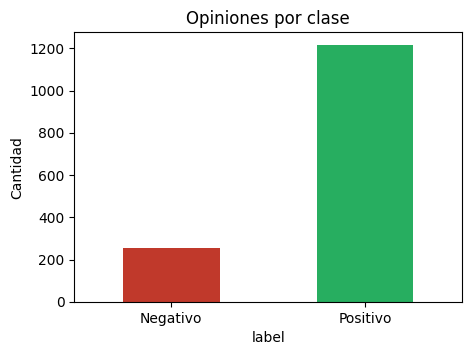

label
Negativo     256
Positivo    1216
Name: count, dtype: int64


In [3]:
print(raw.isna().sum().to_string(), "\n")
print("Duplicados de texto:", raw.duplicated(subset="text").sum())
counts = raw["label"].value_counts().sort_index()
ax = counts.rename(index=LABEL_NAMES).plot(kind="bar", color=["#c0392b", "#27ae60"], figsize=(5, 3.5), title="Opiniones por clase")
ax.set_ylabel("Cantidad"); plt.xticks(rotation=0); plt.show()
print(counts.rename(index=LABEL_NAMES))

In [4]:
# VERIFICA el significado de las etiquetas: 3 ejemplos aleatorios de cada una
for lab in (0, 1):
    print(f"--- label={lab} (se interpreta como {LABEL_NAMES[lab]}) ---")
    for t in raw[raw.label == lab].text.sample(3, random_state=SEED): print(" •", t[:150])

--- label=0 (se interpreta como Negativo) ---
 • La segunda mañana me desperte con picaduras de insectos , me queje pero no hicieron nada .
 • Hotel ' macro ' con dos edificiones en cada lado de la calle , con un uso muy marcado por los clientes de negocios hace que la relación con el cliente
 • Llegando a la madrugada no hubo indicacion concreta ni acompanamiento de personal para poder encontrar rapidamente las habitaciones en semejante compl
--- label=1 (se interpreta como Positivo) ---
 • Sólo tengo que decir una cosa : ¡ Las mejores vacaciones que jamás he pasado !
 • El hotel ha sufrido una reforma en el último año .
 • Muy atentos


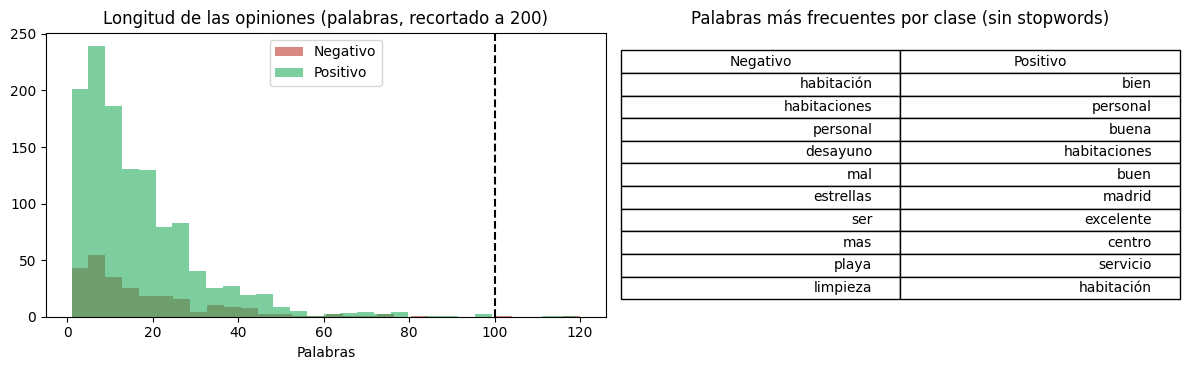

In [5]:
raw["n_palabras"] = raw["text"].astype(str).str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for lab, c in zip((0, 1), ("#c0392b", "#27ae60")):
    ax[0].hist(raw[raw.label == lab].n_palabras.clip(upper=200), bins=30, alpha=0.6, color=c, label=LABEL_NAMES[lab])
ax[0].set(title="Longitud de las opiniones (palabras, recortado a 200)", xlabel="Palabras"); ax[0].legend()
ax[0].axvline(MAX_LEN, color="k", ls="--")

STOP = set("de la que el en y a los se del las un por con no una su para es al lo como más pero sus le ya o este sí porque esta entre cuando muy sin sobre también me hasta hay donde quien desde todo nos durante todos uno les ni contra otros ese eso ante ellos e esto mí antes algunos qué unos yo otro otras otra él tanto esa estos mucho quienes nada muchos cual poco ella estar estas algunas algo nosotros mi mis tú te ti tu tus ellas nosotras vosotros vosotras os mío mía míos mías tuyo tuya tuyos tuyas suyo suya suyos suyas nuestro nuestra nuestros nuestras vuestro vuestra vuestros vuestras esos esas estoy estás está estamos estáis están fue era son ha han he hotel".split())
def top_words(series, n=10):
    c = Counter(w for t in series for w in re.findall(r"[a-záéíóúñü]+", str(t).lower()) if w not in STOP and len(w) > 2)
    return pd.Series(dict(c.most_common(n)))
tw = pd.DataFrame({LABEL_NAMES[l]: top_words(raw[raw.label == l].text).index for l in (0, 1)})
ax[1].axis("off"); ax[1].set_title("Palabras más frecuentes por clase (sin stopwords)")
ax[1].table(cellText=tw.values, colLabels=tw.columns, loc="center").scale(1, 1.4)
plt.tight_layout(); plt.show()

**Observaciones:** la celda siguiente las calcula con los datos reales. Revísalas contra las gráficas y ajusta el texto si algo no coincide.

In [6]:
mx, mn = counts.max(), counts.min()
print(f"- Clases: {len(counts)} | opiniones: {len(raw)} | nulos: {int(raw.text.isna().sum())} | duplicados: {int(raw.duplicated(subset='text').sum())}")
print("- Balance: " + ", ".join(f"{LABEL_NAMES[k]}={v}" for k, v in counts.items()) + f" (razón {mx/mn:.2f}) -> " + ("clases balanceadas." if mx/mn < 1.5 else "hay desbalance; se vigilan precisión y recall por clase."))
q = raw.n_palabras.quantile([.5, .9, .95])
print(f"- Longitud: mediana {q[.5]:.0f} palabras, p90 {q[.9]:.0f}, p95 {q[.95]:.0f}, máximo {raw.n_palabras.max()}.")
print(f"- Por eso se fija MAX_LEN={MAX_LEN}: cubre al {(raw.n_palabras <= MAX_LEN).mean():.0%} de las opiniones sin recortar; las más largas se truncan y las cortas se rellenan (padding).")

- Clases: 2 | opiniones: 1472 | nulos: 0 | duplicados: 0
- Balance: Negativo=256, Positivo=1216 (razón 4.75) -> hay desbalance; se vigilan precisión y recall por clase.
- Longitud: mediana 12 palabras, p90 35, p95 44, máximo 120.
- Por eso se fija MAX_LEN=100: cubre al 100% de las opiniones sin recortar; las más largas se truncan y las cortas se rellenan (padding).


## 4. Limpieza y preprocesamiento

**Limpieza:** se eliminan filas nulas o vacías, se quitan URLs y espacios sobrantes, se descartan opiniones de menos de 3 palabras y se eliminan **duplicados** (si una opinión repetida cae en train y en test, el resultado de test se infla).

**Normalización del texto:** se conservan las tildes (cambian el significado en español). La conversión a minúsculas y la eliminación de puntuación las hace la capa `TextVectorization` **dentro del modelo**, así la app solo envía texto crudo y no hay diferencias entre entrenamiento y predicción.

In [7]:
URL = re.compile(r"https?://\S+|www\.\S+"); SPACES = re.compile(r"\s+")
def clean_text(t):
    return SPACES.sub(" ", URL.sub(" ", str(t))).strip()

n0 = len(raw)
df = raw.dropna(subset=["text", "label"]).copy()
df["text"] = df["text"].map(clean_text); df["label"] = df["label"].astype(int)
df = df[df["text"].str.split().str.len() >= 3]
df = df.drop_duplicates(subset="text").reset_index(drop=True)[["text", "label"]]
print(f"Antes: {n0} | después de la limpieza: {len(df)} (se eliminaron {n0 - len(df)})")
print(df.label.value_counts().rename(index=LABEL_NAMES).to_string())

Antes: 1472 | después de la limpieza: 1370 (se eliminaron 102)
label
Positivo    1131
Negativo     239


## 5. División en entrenamiento, validación y prueba

Split **estratificado** 70 / 15 / 15. El conjunto de prueba solo se usa en la evaluación final.

In [8]:
trval, test = train_test_split(df, test_size=0.15, stratify=df.label, random_state=SEED)
train, val = train_test_split(trval, test_size=0.15 / 0.85, stratify=trval.label, random_state=SEED)
train, val, test = train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)
print(f"train={len(train)}  val={len(val)}  test={len(test)}")
tx, ty = tf.constant(train.text.tolist()), train.label.values
vx, vy = tf.constant(val.text.tolist()), val.label.values
sx, sy = tf.constant(test.text.tolist()), test.label.values

train=958  val=206  test=206


## 6. Vectorización (texto → secuencia de números)

`TextVectorization` convierte cada opinión en una secuencia de **100 enteros** (cada entero es una palabra del vocabulario de 10.000). Se **ajusta (`adapt`) solo con el conjunto de entrenamiento** para no filtrar información de validación ni de test.

In [9]:
vectorizer = layers.TextVectorization(max_tokens=MAX_TOKENS, output_mode="int", output_sequence_length=MAX_LEN, name="vectorizer")
vectorizer.adapt(tx)
vocab = vectorizer.get_vocabulary()
print("Tamaño del vocabulario:", len(vocab), "| primeras palabras:", vocab[:12])
ej = train.text.iloc[0]
print("\nTexto :", ej[:120]); print("Tokens:", vectorizer(tf.constant([ej]))[0].numpy()[:25], "...")

Tamaño del vocabulario: 2772 | primeras palabras: ['', '[UNK]', np.str_('de'), np.str_('y'), np.str_('la'), np.str_('el'), np.str_('en'), np.str_('muy'), np.str_('hotel'), np.str_('que'), np.str_('a'), np.str_('un')]

Texto : Un lugar de excelencia para nuestras vacaciones !
Tokens: [ 11  82   2 939  14 857 133   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0] ...


## 7. Construcción de la red recurrente

Una **RNN** procesa la secuencia paso a paso y mantiene una *memoria* del contexto. Las RNN simples olvidan rápido (problema del gradiente que se desvanece), por eso se usan **GRU** y **LSTM**, que tienen *compuertas* que deciden qué recordar y qué olvidar. Se entrenan **ambas** y se conserva la mejor según la validación.

Arquitectura:
- **Embedding** (64 dim): cada palabra pasa a un vector denso que captura similitud de significado (`mask_zero=True` ignora el relleno).
- **Bidirectional(GRU o LSTM, 64)**: lee la opinión de izquierda a derecha y de derecha a izquierda.
- **Dense(32, ReLU) + Dropout(0.4)** y **Dense(1, sigmoide)**: probabilidad de que la opinión sea positiva.
- Pérdida `binary_crossentropy`, optimizador Adam, `EarlyStopping` y `ReduceLROnPlateau`.
- **Dataset desbalanceado:** hay muchas más opiniones positivas que negativas, así que se usan **pesos de clase** (los errores en la clase minoritaria cuestan más) y el **umbral de decisión** se elige en validación para maximizar el F1 macro, en vez de usar 0.5 por defecto.

In [10]:
def build_model(kind):
    rnn = {"gru": layers.GRU, "lstm": layers.LSTM}[kind]
    inputs = keras.Input(shape=(), dtype=tf.string, name="texto")
    x = vectorizer(inputs)
    x = layers.Embedding(MAX_TOKENS, EMBED_DIM, mask_zero=True)(x)
    x = layers.Bidirectional(rnn(64, dropout=0.2))(x)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    m = keras.Model(inputs, outputs, name=f"opiniones_{kind}")
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    return m

build_model("gru").summary()

Model: "opiniones_gru"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ texto (InputLayer)  │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vectorizer          │ (None, 100)       │          0 │ texto[0][0]       │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 100, 64)   │    640,000 │ vectorizer[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 100)       │          0 │ vectorizer[0][0]  │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     49,920 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      4,128 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         33 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 694,081 (2.65 MB)

 Trainable params: 694,081 (2.65 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Entrenamiento (GRU vs LSTM)

In [11]:
models, histories, val_acc, val_f1, thrs = {}, {}, {}, {}, {}
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, balanced_accuracy_score
cw_arr = compute_class_weight("balanced", classes=np.array([0, 1]), y=ty)
class_weight = {0: float(cw_arr[0]), 1: float(cw_arr[1])}
print("Pesos de clase:", {LABEL_NAMES[k]: round(v, 2) for k, v in class_weight.items()})

def best_threshold(y, p):
    ths = np.arange(0.05, 0.96, 0.01)
    f1s = [f1_score(y, (p >= t).astype(int), average="macro") for t in ths]
    i = int(np.argmax(f1s)); return float(ths[i]), float(f1s[i])

for kind in ("gru", "lstm"):
    print(f"\n=== {kind.upper()} ===")
    m = build_model(kind)
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)]
    h = m.fit(tx, ty, validation_data=(vx, vy), epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=cbs,
              class_weight=class_weight, verbose=2)
    models[kind], histories[kind] = m, h.history
    val_acc[kind] = max(h.history["val_accuracy"])
    thrs[kind], val_f1[kind] = best_threshold(vy, m.predict(vx, verbose=0).reshape(-1))

best = max(val_f1, key=val_f1.get); model = models[best]; THR = thrs[best]
print("\nF1 macro en validación (con su umbral óptimo):", {k: round(v, 4) for k, v in val_f1.items()},
      "| umbrales:", {k: round(v, 2) for k, v in thrs.items()})
print("-> modelo elegido:", best.upper(), "| umbral de decisión:", round(THR, 2))

Pesos de clase: {'Negativo': 2.87, 'Positivo': 0.61}

=== GRU ===
Epoch 1/30
30/30 - 15s - 496ms/step - accuracy: 0.7505 - loss: 0.6918 - val_accuracy: 0.8204 - val_loss: 0.6724 - learning_rate: 0.0010
Epoch 2/30
30/30 - 0s - 16ms/step - accuracy: 0.8664 - loss: 0.6438 - val_accuracy: 0.8495 - val_loss: 0.5183 - learning_rate: 0.0010
Epoch 3/30
30/30 - 0s - 16ms/step - accuracy: 0.9019 - loss: 0.3473 - val_accuracy: 0.8544 - val_loss: 0.7209 - learning_rate: 0.0010
Epoch 4/30
30/30 - 0s - 15ms/step - accuracy: 0.9520 - loss: 0.1683 - val_accuracy: 0.8641 - val_loss: 0.5785 - learning_rate: 0.0010
Epoch 5/30
30/30 - 0s - 15ms/step - accuracy: 0.9823 - loss: 0.0878 - val_accuracy: 0.8641 - val_loss: 0.4278 - learning_rate: 5.0000e-04
Epoch 6/30
30/30 - 0s - 15ms/step - accuracy: 0.9927 - loss: 0.0450 - val_accuracy: 0.8738 - val_loss: 0.4182 - learning_rate: 5.0000e-04
Epoch 7/30
30/30 - 0s - 15ms/step - accuracy: 0.9948 - loss: 0.0271 - val_accuracy: 0.8786 - val_loss: 0.4772 - learning

## 9. Gráficas del entrenamiento

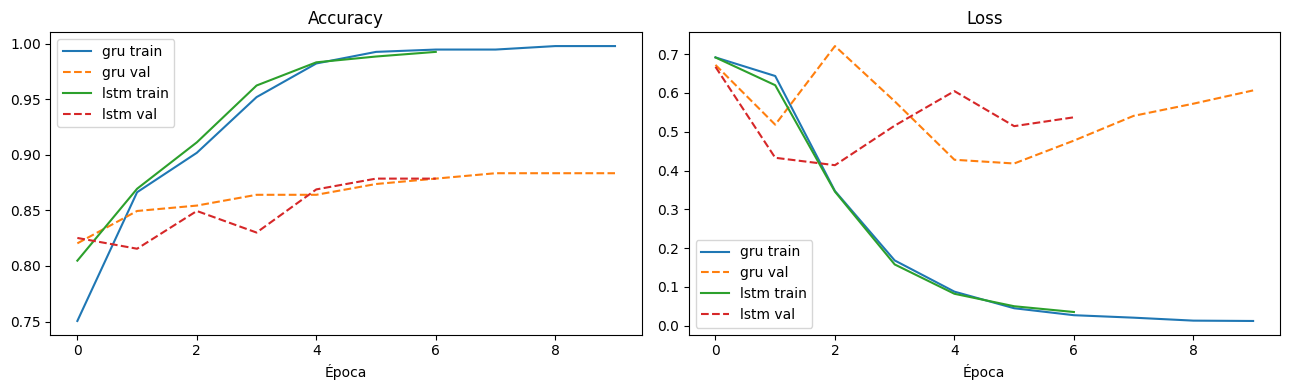

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for kind, h in histories.items():
    ax[0].plot(h["accuracy"], label=f"{kind} train"); ax[0].plot(h["val_accuracy"], "--", label=f"{kind} val")
    ax[1].plot(h["loss"], label=f"{kind} train"); ax[1].plot(h["val_loss"], "--", label=f"{kind} val")
ax[0].set(title="Accuracy", xlabel="Época"); ax[1].set(title="Loss", xlabel="Época")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

**Análisis:** la celda siguiente resume las curvas con números reales.

In [13]:
for kind, h in histories.items():
    va, ta = np.array(h["val_accuracy"]), np.array(h["accuracy"])
    b = int(np.argmin(h["val_loss"]))
    print(f"- {kind.upper()}: {len(va)} épocas; mejor val_loss en la época {b+1} (val_acc {va[b]:.3f}, train_acc {ta[b]:.3f}, brecha {ta[b]-va[b]:+.3f}); "
          + ("posible sobreajuste." if ta[b] - va[b] > 0.10 else "sin sobreajuste marcado."))
print(f"- Modelo elegido: {best.upper()} (mayor F1 macro en validación). La diferencia con el otro es de {abs(val_f1['gru']-val_f1['lstm']):.3f}; si es pequeña, ambos rinden de forma parecida.")

- GRU: 10 épocas; mejor val_loss en la época 6 (val_acc 0.874, train_acc 0.993, brecha +0.119); posible sobreajuste.
- LSTM: 7 épocas; mejor val_loss en la época 3 (val_acc 0.850, train_acc 0.911, brecha +0.062); sin sobreajuste marcado.
- Modelo elegido: GRU (mayor F1 macro en validación). La diferencia con el otro es de 0.004; si es pequeña, ambos rinden de forma parecida.


## 10. Evaluación con métricas apropiadas

Se evalúa **solo ahora** con el conjunto de prueba. Como las clases están desbalanceadas, el **accuracy engaña**: un modelo que siempre responda "positivo" ya acertaría el porcentaje de positivas (la **línea base**). Por eso se reportan además **balanced accuracy, F1 macro, precisión/recall/F1 por clase y ROC-AUC**, y se mira sobre todo el recall de la clase minoritaria (negativas), que es la que más interesa al taller.

In [14]:
prob = model.predict(sx, verbose=0).reshape(-1)
pred = (prob >= THR).astype(int)
test_acc = float((pred == sy).mean()); test_auc = float(roc_auc_score(sy, prob))
baseline = float(max((sy == 0).mean(), (sy == 1).mean()))
test_bacc = float(balanced_accuracy_score(sy, pred)); test_f1 = float(f1_score(sy, pred, average="macro"))
print(f"Umbral de decisión: {THR:.2f} (elegido en validación)")
print(f"Test accuracy: {test_acc:.4f} | línea base (siempre la clase mayoritaria): {baseline:.4f}")
print(f"Balanced accuracy: {test_bacc:.4f} | F1 macro: {test_f1:.4f} | ROC-AUC: {test_auc:.4f}\n")
print(classification_report(sy, pred, target_names=[LABEL_NAMES[0], LABEL_NAMES[1]]))

Umbral de decisión: 0.27 (elegido en validación)
Test accuracy: 0.8641 | línea base (siempre la clase mayoritaria): 0.8252
Balanced accuracy: 0.6768 | F1 macro: 0.7107 | ROC-AUC: 0.8663

              precision    recall  f1-score   support

    Negativo       0.70      0.39      0.50        36
    Positivo       0.88      0.96      0.92       170

    accuracy                           0.86       206
   macro avg       0.79      0.68      0.71       206
weighted avg       0.85      0.86      0.85       206



## 11. Matriz de confusión y curva ROC

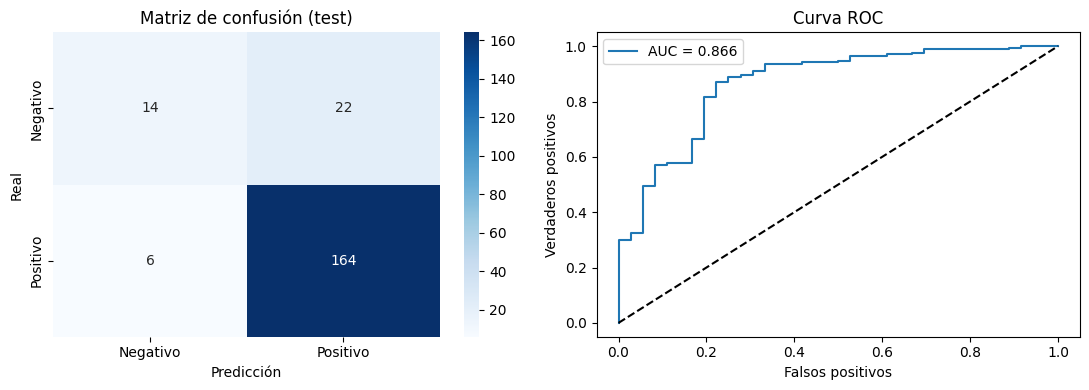

In [15]:
cm = confusion_matrix(sy, pred)
names = [LABEL_NAMES[0], LABEL_NAMES[1]]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=names, yticklabels=names, ax=ax[0])
ax[0].set(title="Matriz de confusión (test)", xlabel="Predicción", ylabel="Real")
fpr, tpr, _ = roc_curve(sy, prob)
ax[1].plot(fpr, tpr, label=f"AUC = {test_auc:.3f}"); ax[1].plot([0, 1], [0, 1], "k--")
ax[1].set(title="Curva ROC", xlabel="Falsos positivos", ylabel="Verdaderos positivos"); ax[1].legend()
plt.tight_layout(); plt.show()

In [16]:
recall = cm.diagonal() / cm.sum(axis=1)
print("- Recall por clase: " + ", ".join(f"{n}={r:.2f}" for n, r in zip(names, recall)))
print(f"- Falsos positivos (negativas leídas como positivas): {cm[0, 1]} | falsos negativos (positivas leídas como negativas): {cm[1, 0]}.")
print("- " + ("El modelo falla más con las opiniones negativas (las lee como positivas), justo las que más interesan al taller." if cm[0, 1] > cm[1, 0] else "El modelo falla más con las positivas; las negativas se detectan mejor." if cm[1, 0] > cm[0, 1] else "Los dos tipos de error ocurren con la misma frecuencia."))

- Recall por clase: Negativo=0.39, Positivo=0.96
- Falsos positivos (negativas leídas como positivas): 22 | falsos negativos (positivas leídas como negativas): 6.
- El modelo falla más con las opiniones negativas (las lee como positivas), justo las que más interesan al taller.


## 12. Predicciones de prueba (12 opiniones del conjunto de test)

In [17]:
pd.set_option("display.max_colwidth", 110)
idx = np.random.default_rng(SEED).choice(len(test), size=min(12, len(test)), replace=False)
tabla = pd.DataFrame({
    "opinión": test.text.iloc[idx].str.slice(0, 110).values,
    "real": [LABEL_NAMES[i] for i in sy[idx]],
    "predicción": [LABEL_NAMES[i] for i in pred[idx]],
    "prob_positivo": prob[idx].round(3),
})
tabla["acierto"] = np.where(tabla.real == tabla["predicción"], "✔", "✘")
tabla

,opinión,real,predicción,prob_positivo,acierto
0,Me ha gustado,Positivo,Positivo,0.965,✔
1,"Buen servicio , todo muy limpio y cómodo .",Positivo,Positivo,1.000,✔
2,Pedazo de hotel,Positivo,Positivo,0.367,✔
3,"Si vas con coche , es muy buena opción y el tren que viene del aeropuerto esta a dos paradas de tranvía de...",Positivo,Positivo,1.000,✔
4,Totalmente recomendable por su precio y situación estratégica,Positivo,Positivo,0.999,✔
5,Me parece fenomenal el tema del wifi gratuíto y que admás funcina muy bien .,Positivo,Positivo,0.956,✔
6,Nos pusieron cama supletoria junto a la cama grande .,Positivo,Positivo,0.957,✔
7,Seguramente volveremos .,Positivo,Positivo,0.872,✔
8,"Destaca por su compromiso con el huesped , desde la recepcion , al bar · restaurante , pasando por sus mag...",Positivo,Positivo,1.000,✔
9,El Spa está bastante bien .,Positivo,Positivo,0.992,✔


## 13. Guardado del modelo

El modelo guardado incluye la vectorización, por lo que recibe **texto crudo**.

In [18]:
pathlib.Path("models").mkdir(exist_ok=True)
model.save("models/opiniones_rnn.keras")
json.dump({"tipo": best, "umbral": THR, "test_accuracy": test_acc, "linea_base": baseline,
           "balanced_accuracy": test_bacc, "f1_macro": test_f1, "roc_auc": test_auc, "val_f1_macro": val_f1},
          open("models/model_info.json", "w"), indent=2)
# comprobación: se recarga y se obtiene la misma predicción
rec = keras.models.load_model("models/opiniones_rnn.keras")
print("Recarga OK | diferencia máxima de predicción:", float(np.abs(rec.predict(sx, verbose=0).reshape(-1) - prob).max()))
try:
    from google.colab import files
    files.download("models/opiniones_rnn.keras"); files.download("models/model_info.json")
except ImportError:
    pass

Recarga OK | diferencia máxima de predicción: 0.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Prueba con opiniones de un taller de motos

Opiniones escritas a mano (**no son datos del dataset ni se usan para las métricas**), solo para ver cómo se comporta el modelo fuera de su dominio (hoteles).

In [19]:
ejemplos = [
    "Excelente servicio, me arreglaron la moto rápido y quedó funcionando perfecto.",
    "Muy mala atención, tardaron una semana y la moto quedó peor que antes.",
    "El mecánico fue amable y honesto, me explicó todo y el precio fue justo.",
    "Me cobraron de más y no solucionaron el problema, no vuelvo.",
    "Buen taller, repuestos originales y entrega puntual.",
    "Pésimo, el cambio de aceite lo hicieron mal y todavía gotea.",
]
p = model.predict(tf.constant([clean_text(t) for t in ejemplos]), verbose=0).reshape(-1)
pd.DataFrame({"opinión": ejemplos, "predicción": [LABEL_NAMES[int(x >= THR)] for x in p], "prob_positivo": p.round(3)})

,opinión,predicción,prob_positivo
0,"Excelente servicio, me arreglaron la moto rápido y quedó funcionando perfecto.",Positivo,1.000
1,"Muy mala atención, tardaron una semana y la moto quedó peor que antes.",Positivo,0.895
2,"El mecánico fue amable y honesto, me explicó todo y el precio fue justo.",Positivo,0.999
3,"Me cobraron de más y no solucionaron el problema, no vuelvo.",Negativo,0.001
4,"Buen taller, repuestos originales y entrega puntual.",Positivo,0.986
5,"Pésimo, el cambio de aceite lo hicieron mal y todavía gotea.",Negativo,0.014


## 15. Conclusiones y resumen de resultados

La celda siguiente genera `reports/resultados.md` con los números reales; copia su contenido a la sección *Resultados* del README.

In [20]:
pathlib.Path("reports").mkdir(exist_ok=True)
fp, fn = int(cm[0, 1]), int(cm[1, 0])
txt = f"""## Resultados

- Dataset: {len(df)} opiniones tras la limpieza ({", ".join(f"{LABEL_NAMES[k]}={v}" for k, v in df.label.value_counts().sort_index().items())}).
- Split: train={len(train)}, val={len(val)}, test={len(test)}.
- Modelos comparados (F1 macro en validación): {", ".join(f"{k.upper()}={v:.3f}" for k, v in val_f1.items())}. Elegido: **{best.upper()} bidireccional**, con pesos de clase y umbral de decisión {THR:.2f} (elegido en validación).
- **Accuracy en test: {test_acc:.3f}** frente a una línea base de {baseline:.3f} (siempre la clase mayoritaria). Balanced accuracy: {test_bacc:.3f} | F1 macro: {test_f1:.3f} | ROC-AUC: {test_auc:.3f}.
- Recall por clase: {", ".join(f"{n}={r:.2f}" for n, r in zip(names, recall))}.
- Errores en test: {fp} negativas leídas como positivas y {fn} positivas leídas como negativas.

## Conclusiones

- La red recurrente bidireccional ({best.upper()}) alcanza {test_acc:.1%} de accuracy sobre datos no vistos frente a {baseline:.1%} de la línea base; el F1 macro ({test_f1:.2f}) y el recall por clase muestran mejor que el accuracy qué tan bien se detectan las opiniones negativas.
- {"El error más frecuente es leer como positivas opiniones negativas, justo las que más importan a un taller." if fp > fn else "Las opiniones negativas se detectan mejor que las positivas." if fn > fp else "Los dos tipos de error ocurren con la misma frecuencia."}
- Limitaciones: el dataset es pequeño y de opiniones de hoteles, no de talleres de moto; con otro vocabulario el modelo pierde precisión.
- Mejoras: reunir opiniones reales de talleres, usar embeddings preentrenados en español o un modelo tipo transformer, y añadir una clase neutral.
"""
pathlib.Path("reports/resultados.md").write_text(txt, encoding="utf-8")
print(txt)

## Resultados

- Dataset: 1370 opiniones tras la limpieza (Negativo=239, Positivo=1131).
- Split: train=958, val=206, test=206.
- Modelos comparados (F1 macro en validación): GRU=0.779, LSTM=0.774. Elegido: **GRU bidireccional**, con pesos de clase y umbral de decisión 0.27 (elegido en validación).
- **Accuracy en test: 0.864** frente a una línea base de 0.825 (siempre la clase mayoritaria). Balanced accuracy: 0.677 | F1 macro: 0.711 | ROC-AUC: 0.866.
- Recall por clase: Negativo=0.39, Positivo=0.96.
- Errores en test: 22 negativas leídas como positivas y 6 positivas leídas como negativas.

## Conclusiones

- La red recurrente bidireccional (GRU) alcanza 86.4% de accuracy sobre datos no vistos frente a 82.5% de la línea base; el F1 macro (0.71) y el recall por clase muestran mejor que el accuracy qué tan bien se detectan las opiniones negativas.
- El error más frecuente es leer como positivas opiniones negativas, justo las que más importan a un taller.
- Limitaciones: el dataset es peq